# Clustering Part 2 — Agglomerative Hierarchical Clustering on CC GENERAL

**Review 2 notebook.** Includes dataset audit, EDA, cleaning, scaling, dendrograms comparing linkage strategies, Agglomerative cluster assignments, all three required metrics, PCA visualization, and cluster profiling.

**Compute note:** hierarchical clustering and dendrograms are memory-intensive. This notebook uses a reproducible sample of up to 3,000 customers for model fitting and up to 1,000 for dendrogram comparison. Report these sample sizes clearly. Cluster IDs are arbitrary and there is no target column used during fitting.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load dataset

In [2]:
# Locate the uploaded dataset whether this notebook is run from the project root or notebooks/.
candidates = [
    Path("CC_GENERAL.csv"), Path("CC GENERAL.csv"), Path("CC GENERAL(1).csv"), Path("CC GENERAL(2).csv"),
    Path("data/CC_GENERAL.csv"), Path("../data/CC_GENERAL.csv"), Path("data/CC GENERAL.csv"), Path("../data/CC GENERAL.csv"),
    Path("../CC GENERAL.csv"), Path("../CC GENERAL(1).csv")
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Place CC GENERAL.csv beside this notebook or in a data/ folder.")

df = pd.read_csv(data_path)
print(f"Loaded: {data_path} | Shape: {df.shape}")
display(df.head())

Loaded: ../data/CC_GENERAL.csv | Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 2. Dataset audit

In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values in raw dataset:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Duplicate rows:", df.duplicated().sum())
print("Numeric summary:")
display(df.describe().T)

Data types:


,dtype
CUST_ID,object
BALANCE,float64
BALANCE_FREQUENCY,float64
PURCHASES,float64
ONEOFF_PURCHASES,float64
INSTALLMENTS_PURCHASES,float64
CASH_ADVANCE,float64
PURCHASES_FREQUENCY,float64
ONEOFF_PURCHASES_FREQUENCY,float64
PURCHASES_INSTALLMENTS_FREQUENCY,float64


Missing values in raw dataset:


,missing
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
CUST_ID,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0


Duplicate rows: 0
Numeric summary:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


## 3. EDA — distributions

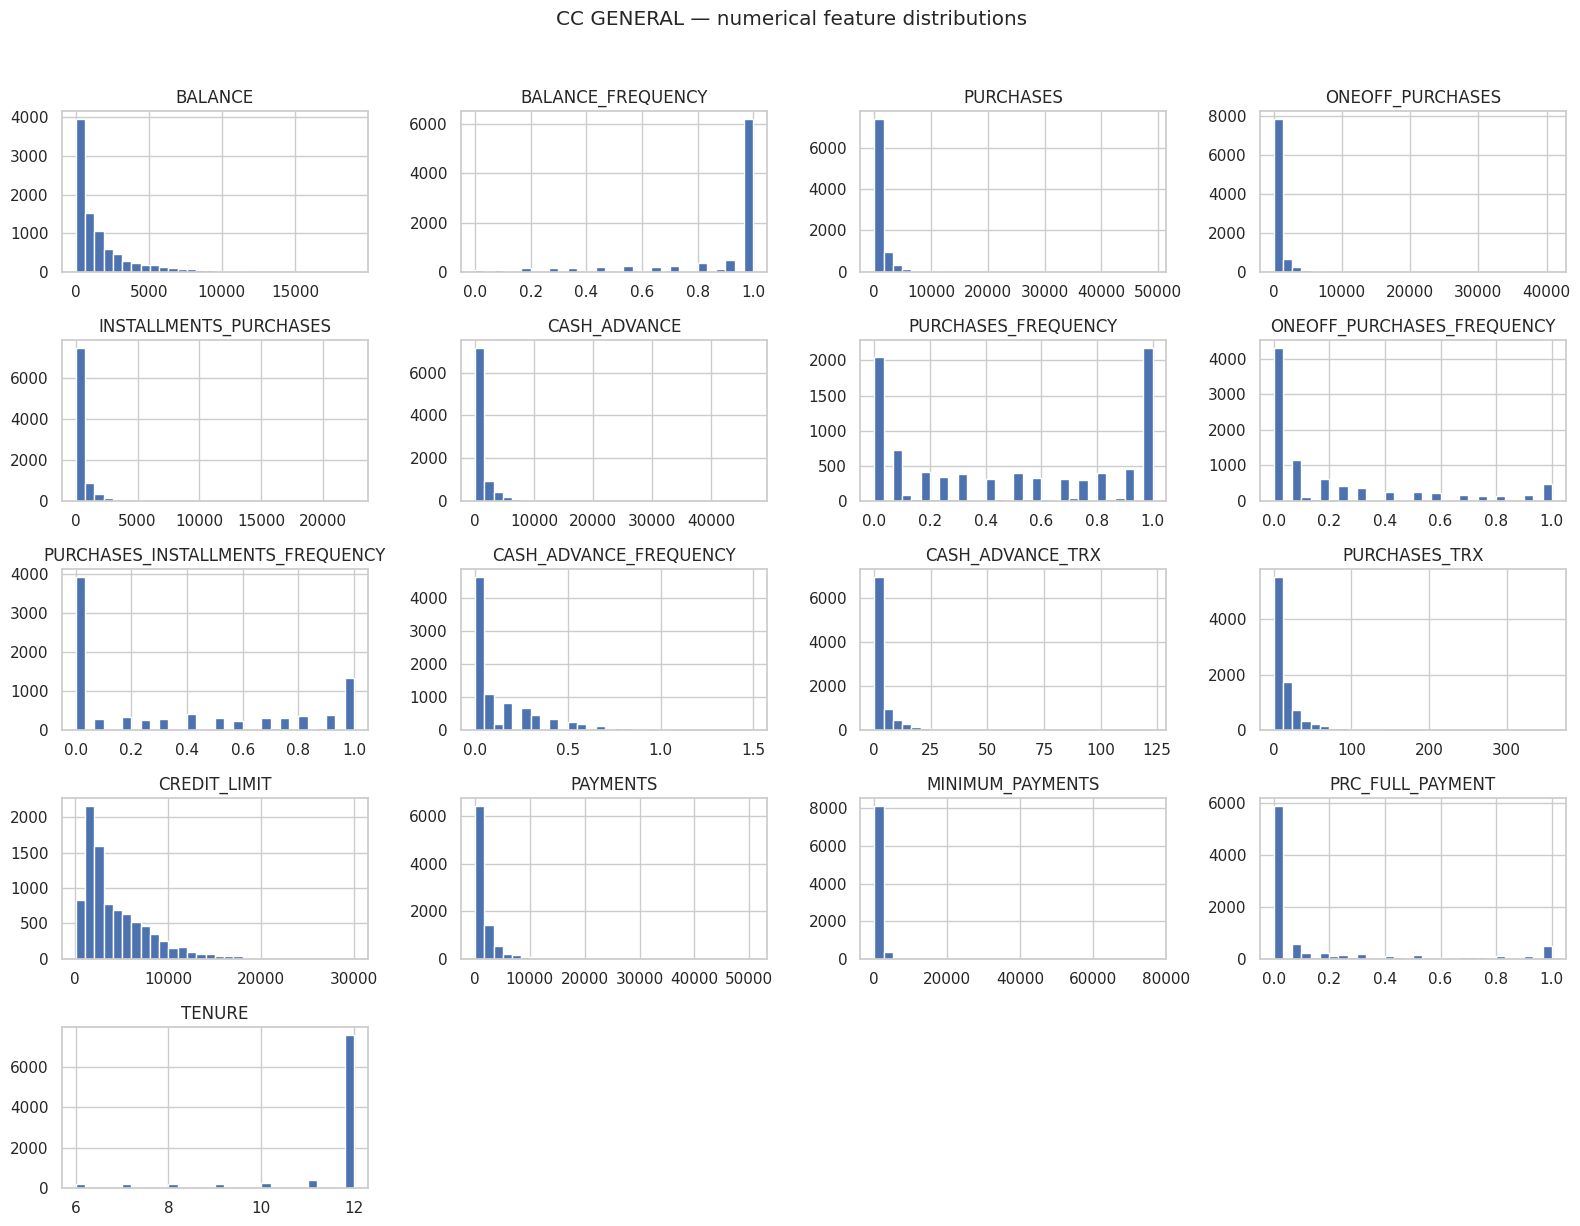

In [4]:
# Raw numeric feature distributions (log-like skew is expected for monetary variables).
raw_numeric = df.select_dtypes(include=np.number).drop(columns=["CUST_ID"], errors="ignore")
raw_numeric.hist(figsize=(16, 12), bins=30, layout=(-1, 4))
plt.suptitle("CC GENERAL — numerical feature distributions", y=1.02)
plt.tight_layout()
plt.show()

## Cleaning and scaling

Missing numeric values are imputed with the median. The identifier is removed, and features are standardized before distance-based clustering. Keep the preprocessing choices and their reasons in the final report.

In [5]:
# CUST_ID is an identifier, not a meaningful distance-based feature.
# There is no target column used to fit clustering models.
work = df.drop(columns=["CUST_ID"], errors="ignore").copy()
work = work.apply(pd.to_numeric, errors="coerce")

print("Missing values before imputation:")
display(work.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Duplicate rows:", work.duplicated().sum())

# Median imputation is robust to skewed spending variables; standardization prevents
# high-magnitude monetary columns from dominating distance calculations.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(work)
feature_names = work.columns.tolist()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_names)
print("Scaled feature matrix:", X_scaled.shape)

Missing values before imputation:


,missing
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


Duplicate rows: 0
Scaled feature matrix: (8950, 17)


## 4. Prepare reproducible modeling sample

In [6]:
# Hierarchical clustering stores pairwise relationships; sample to limit memory and runtime.
rng = np.random.default_rng(RANDOM_STATE)
MODEL_SAMPLE_SIZE = min(1000, len(X_scaled))
model_idx = rng.choice(len(X_scaled), size=MODEL_SAMPLE_SIZE, replace=False)
X_model = X_scaled[model_idx]
source_rows = df.iloc[model_idx].reset_index(drop=True)
print("Rows used for Agglomerative model:", len(X_model))

Rows used for Agglomerative model: 1000


## 5. Dendrogram — compare linkage strategies

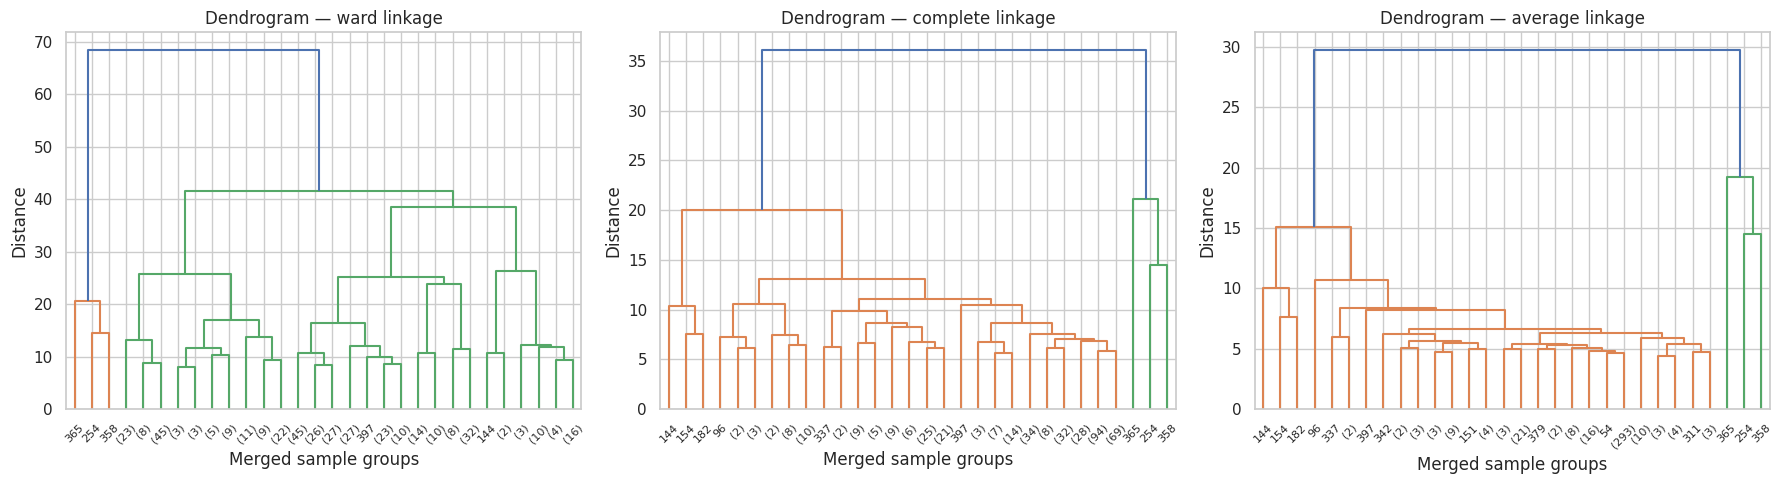

Dendrograms computed on 400 rows; truncated to last 30 merged groups for readability.


In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram

DENDROGRAM_SAMPLE_SIZE = min(400, len(X_model))
dendro_idx = np.arange(DENDROGRAM_SAMPLE_SIZE)  # deterministic subset of the sampled matrix
X_dendro = X_model[dendro_idx]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, method in zip(axes, ["ward", "complete", "average"]):
    Z = linkage(X_dendro, method=method, metric="euclidean")
    dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, leaf_font_size=8, ax=ax)
    ax.set_title(f"Dendrogram — {method} linkage")
    ax.set_xlabel("Merged sample groups")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()
print(f"Dendrograms computed on {DENDROGRAM_SAMPLE_SIZE} rows; truncated to last 30 merged groups for readability.")

## 6. Fit Agglomerative Clustering and generate labels

In [8]:
# Ward linkage is a common starting choice for standardized numeric data.
# Choose k after reviewing the dendrogram and compare linkage choices below.
K_CHOSEN = 4
LINKAGE_CHOSEN = "ward"

agg = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=LINKAGE_CHOSEN)
agg_labels = agg.fit_predict(X_model)
clustered_sample = source_rows.copy()
clustered_sample["Cluster"] = agg_labels
print("Cluster counts:")
display(clustered_sample["Cluster"].value_counts().sort_index().rename("customers").to_frame())
display(clustered_sample[["Cluster"]].head())

Cluster counts:


,customers
Cluster,
0,69
1,496
2,431
3,4


,Cluster
0,1
1,1
2,2
3,1
4,1


## 7. Compare linkage strategies using evaluation metrics

In [9]:
linkage_results = []
for method in ["ward", "complete", "average"]:
    model = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=method)
    labels = model.fit_predict(X_model)
    linkage_results.append({
        "Linkage": method,
        "Silhouette Score": silhouette_score(X_model, labels, sample_size=min(2000, len(X_model)), random_state=RANDOM_STATE),
        "Davies–Bouldin Index": davies_bouldin_score(X_model, labels),
        "Calinski–Harabasz Index": calinski_harabasz_score(X_model, labels),
    })
linkage_comparison = pd.DataFrame(linkage_results).set_index("Linkage")
display(linkage_comparison.round(4))
print("Higher silhouette and Calinski–Harabasz are generally better; lower Davies–Bouldin is generally better.")

,Silhouette Score,Davies–Bouldin Index,Calinski–Harabasz Index
Linkage,,,
ward,0.1865,1.4823,163.7347
complete,0.8091,0.4138,102.6134
average,0.8064,0.4889,108.1784


Higher silhouette and Calinski–Harabasz are generally better; lower Davies–Bouldin is generally better.


## 8. Required metrics for selected Agglomerative model

In [10]:
agg_metrics = {
    "Silhouette Score (sample up to 2000)": silhouette_score(X_model, agg_labels, sample_size=min(2000, len(X_model)), random_state=RANDOM_STATE),
    "Davies–Bouldin Index": davies_bouldin_score(X_model, agg_labels),
    "Calinski–Harabasz Index": calinski_harabasz_score(X_model, agg_labels),
}
display(pd.DataFrame([agg_metrics], index=[f"Agglomerative ({LINKAGE_CHOSEN})"]).T.rename(columns={f"Agglomerative ({LINKAGE_CHOSEN})":"Score"}))

,Score
Silhouette Score (sample up to 2000),0.186498
Davies–Bouldin Index,1.482255
Calinski–Harabasz Index,163.734674


## 9. PCA — 2D cluster visualization

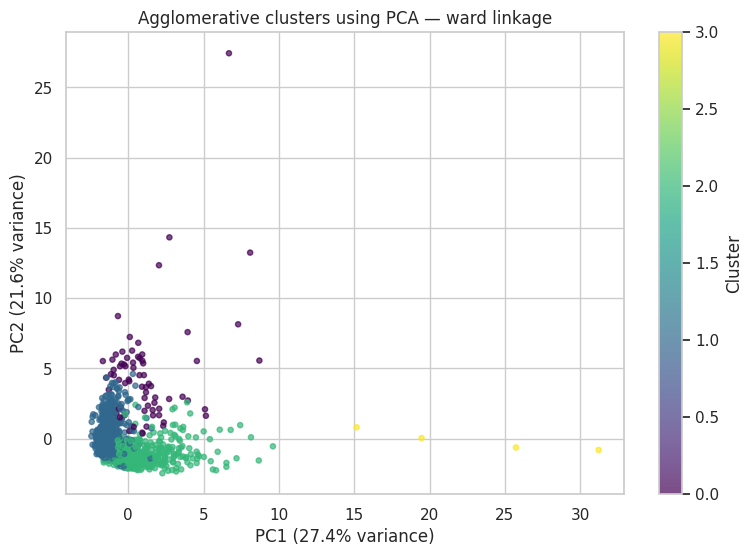

Total variance explained by 2 PCs: 0.4903


In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_model)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap="viridis", s=14, alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title(f"Agglomerative clusters using PCA — {LINKAGE_CHOSEN} linkage")
plt.colorbar(scatter, label="Cluster")
plt.show()
print("Total variance explained by 2 PCs:", round(pca.explained_variance_ratio_.sum(), 4))

## 10. Cluster profile interpretation

In [12]:
# Profile in original units for the rows included in the hierarchical model.
profile = source_rows.drop(columns=["CUST_ID"], errors="ignore").copy()
profile["Cluster"] = agg_labels
display(profile.groupby("Cluster").mean(numeric_only=True).round(2))
display(profile["Cluster"].value_counts().sort_index().rename("sample_customer_count").to_frame())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,5864.73,0.95,1014.83,519.40,495.43,6986.31,0.46,0.17,0.39,0.44,16.67,18.58,9550.72,6181.03,4600.53,0.04,11.59
1,1454.59,0.84,245.10,169.24,75.86,1061.99,0.18,0.07,0.11,0.19,3.79,2.96,3652.43,1110.74,579.74,0.05,11.17
2,1044.07,0.92,1634.69,933.07,702.31,188.86,0.83,0.35,0.64,0.04,0.80,25.85,4817.99,1680.41,582.50,0.28,11.97
3,3997.34,1.00,31336.06,23096.82,8239.25,117.27,1.00,0.92,0.85,0.02,0.25,217.00,14125.00,27768.63,1001.53,0.62,12.00


,sample_customer_count
Cluster,
0,69
1,496
2,431
3,4


## 11. Save cluster assignments

In [13]:
clustered_sample["source_row_index"] = model_idx
output_path = Path("CC_GENERAL_agglomerative_cluster_assignments_sample.csv")
clustered_sample.to_csv(output_path, index=False)
print(f"Saved sample assignments to: {output_path.resolve()}")

Saved sample assignments to: /mnt/data/Review-2-Final/Review-2/notebooks/CC_GENERAL_agglomerative_cluster_assignments_sample.csv


### Findings to complete after execution

- Why was the final linkage strategy selected?
- What does the dendrogram suggest about possible cluster counts?
- Compare the three metrics across linkage strategies:
- What distinguishes the resulting clusters based on profile means?
- Limitations of hierarchical clustering on a reproducible sample: